<h2>IS453 Financial Analytics</h2><h2>Group Assignment - Home Improvement Loan Scorecard</h2>

### Step 7: Scorecard Analysis and Scaling

This notebook follows `06_scorecard creation.ipynb`. In Step 6 we built the logistic regression on our final characteristics and its scorecard on a reference scale (600 points at the training sample's own bad:good odds, PDO 20). In this notebook we:

1. check that the model's predicted PDs are well calibrated (7.1)
2. set out our financial assumptions, which can be edited (7.2)
3. find the **profit-maximising** cutoff with a Net Profit vs Risk Tolerance analysis on the training sample (7.3-7.4)
4. choose a final score scale that puts our cutoff at 600 (7.5)
5. apply that scale and save the final scorecard (7.6)
6. compare confusion matrices and F1 before and after the profit-based cutoff, as in the Week 11 lab (7.7)
7. run end-to-end checks (7.8) and summarise the results (7.9)

We **load** the model, bins and reference-scale scorecard from Step 6; nothing is re-binned or re-fitted.

In [1]:
# ignore scorecardpy compatibility warnings
import warnings
warnings.filterwarnings('ignore')

import os
import json
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import linear_model, metrics
from sklearn.model_selection import StratifiedKFold, cross_val_predict
import scorecardpy as sc
from IPython.display import display, Markdown

pd.set_option('display.max_columns', 60)
pd.set_option('display.max_rows', 300)
pd.set_option('display.max_colwidth', 120)
pd.set_option('display.width', 200)
plt.rcParams['figure.dpi'] = 80

## 7.0 Load the Step 6 Model and Data

- `data/step6_scorecard_model.pkl`: our bins, the fitted logistic regression, the reference-scale scorecard and its parameters (Step 6, 6.13)
- `data/final_characteristics.csv`: raw characteristic values
- `data/encoded.csv`: WOE values of the 12 final characteristics
- `data/train_test_split.csv`: the train/test split we have used since Step 5

We recalculate the PDs and scores from the loaded model and check them against the values saved in Step 6.

In [2]:
with open('data/step6_scorecard_model.pkl', 'rb') as f:
    step6 = pickle.load(f)
bins, lr, card = step6['bins'], step6['lr'], step6['card']
LR_CONFIG, configs, MODEL_X = step6['LR_CONFIG'], step6['configs'], step6['MODEL_X']
breaks_list, formula, coefficients, perf = step6['breaks_list'], step6['formula'], step6['coefficients'], step6['perf']
POINTS0, PDO, ODDS0_REFERENCE = step6['POINTS0'], step6['PDO'], step6['ODDS0_REFERENCE']
TARGET_BAD_RATE = step6['TARGET_BAD_RATE']
X_COLS, REMOVED_FOR_SIGN = step6['X_COLS'], step6['REMOVED_FOR_SIGN']

ID, TARGET = 'SK_ID_CURR', 'TARGET'
final_original = pd.read_csv('data/final_characteristics.csv')
split_ids = pd.read_csv('data/train_test_split.csv')
with open('data/coarse_classing_bins.json') as f:
    approved_bins = json.load(f)

# same train/test construction as Step 6
data = final_original.merge(split_ids, on=ID, how='left', validate='one_to_one')
train = data[data['SAMPLE'] == 'train'].drop(columns='SAMPLE').reset_index(drop=True)
test = data[data['SAMPLE'] == 'test'].drop(columns='SAMPLE').reset_index(drop=True)
y_train, y_test = train[TARGET], test[TARGET]

MODEL_WOE = [f'{c}_woe' for c in MODEL_X]
encoded_woe = pd.read_csv('data/encoded.csv').set_index(ID)
X_train = encoded_woe.loc[train[ID], MODEL_WOE].reset_index(drop=True)
X_test = encoded_woe.loc[test[ID], MODEL_WOE].reset_index(drop=True)

pd_train, pd_test = lr.predict_proba(X_train)[:, 1], lr.predict_proba(X_test)[:, 1]
train['score'] = sc.scorecard_ply(train[MODEL_X], card)['score'].values
test['score'] = sc.scorecard_ply(test[MODEL_X], card)['score'].values

FACTOR = PDO / np.log(2)
OFFSET = POINTS0 + FACTOR * np.log(ODDS0_REFERENCE)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=186)

loaded = {
    'Model characteristics': f'{len(MODEL_X)}: ' + ', '.join(MODEL_X),
    'Training / testing applicants': f'{len(train):,} / {len(test):,}',
    'PDs equal to Step 6': bool(np.allclose(np.concatenate([pd_train, pd_test]), step6['pd_12'].loc[np.concatenate([train[ID], test[ID]])].values)),
    'Reference-scale scores equal to Step 6': bool((np.concatenate([train['score'], test['score']]) == step6['score_reference'].loc[np.concatenate([train[ID], test[ID]])].values).all()),
    'Reference scale': f'{POINTS0} at 1 : {1 / ODDS0_REFERENCE:.2f}, PDO {PDO}',
}
display(pd.DataFrame({'Loaded from Step 6': loaded}))
assert loaded['PDs equal to Step 6'] and loaded['Reference-scale scores equal to Step 6']

,Loaded from Step 6
Model characteristics,"11: EMPLOYMENT_YEARS, CREDIT_TO_GOODS_RATIO, ACTIVE_LOAN_RATIO, MOST_RECENT_CREDIT_AGE, OCCUPATION_TYPE, OLDEST_CRED..."
Training / testing applicants,"149,318 / 63,994"
PDs equal to Step 6,True
Reference-scale scores equal to Step 6,True
Reference scale,"600 at 1 : 11.56, PDO 20"


In [3]:
# helper used for the points tables: every characteristic and bin with WOE, coefficient and points
coef_by_var = dict(zip(MODEL_X, lr.coef_[0]))

def full_scorecard(card):
    t = pd.concat([card[v][['variable', 'bin', 'points']].merge(bins[v][['bin', 'count', 'badprob', 'woe']], on='bin', how='left')
                   for v in MODEL_X], ignore_index=True)
    t['coefficient'] = t['variable'].map(coef_by_var)
    t = t[['variable', 'bin', 'count', 'badprob', 'woe', 'coefficient', 'points']]
    t.columns = ['Characteristic', 'Bin', 'Training applicants', 'Bad rate', 'WOE (scorecardpy)', 'Regression coefficient', 'Points']
    assert t['Points'].notnull().all() and set(t['Characteristic']) == set(MODEL_X)
    return t

card_fmt = {'Training applicants': '{:,}', 'Bad rate': '{:.2%}', 'WOE (scorecardpy)': '{:+.4f}', 'Regression coefficient': '{:+.4f}', 'Points': '{:.0f}'}
scorecard_table = full_scorecard(card)
print(f'Reference-scale scorecard: {len(MODEL_X)} characteristics, {len(scorecard_table)} bins')

Reference-scale scorecard: 11 characteristics, 51 bins


## 7.1 Inspection of the Scorecard and PD Calibration

A common rule of thumb sets the cutoff where the bad rate of approved applicants is at most 5%. We call this the **original policy**. It is convenient, but it is not a business goal. In 7.1-7.6 we choose the cutoff by **expected net profit** instead, and only then line the score scale up with that decision.

We reuse what we saved in Step 6 (7.0): the Step 5 bins (`bins`), the fitted logistic regression (`lr`), the reference-scale scorecard (`card`) and its applicant scores. Nothing is re-binned or re-fitted.

First we confirm the set-up from the objects in memory.

In [4]:
current_config = pd.DataFrame({'Value': {
    'Target score': POINTS0,
    'Target odds (bad:good)': f'1 : {1 / ODDS0_REFERENCE:.2f}',
    'PDO': PDO,
    'Test ROC AUC': f'{perf.loc["ROC AUC (predicted PD)", "Test"]:.4f}',
    'Logistic regression configuration': LR_CONFIG,
    'Characteristics in the model': len(MODEL_X),
    'Higher score = lower PD (Spearman, train)': f'{pd.Series(train["score"].values).corr(pd.Series(pd_train), method="spearman"):.4f}',
}})
display(current_config)

,Value
Target score,600
Target odds (bad:good),1 : 11.56
PDO,20
Test ROC AUC,0.6697
Logistic regression configuration,Standard
Characteristics in the model,11
"Higher score = lower PD (Spearman, train)",-0.9996


### Probability calibration check

Expected credit loss uses each applicant's predicted PD, so the PDs have to be realistic, not just in the right order. Our model is unweighted (we rejected class weighting in Step 6, 6.6.1, because it pushed the average PD up to about 46%). Below we group applicants into 10 equal-sized PD bands and compare the average predicted PD with the observed bad rate in each band, on both samples.

Largest gap between mean predicted PD and observed bad rate in any band: 0.81%


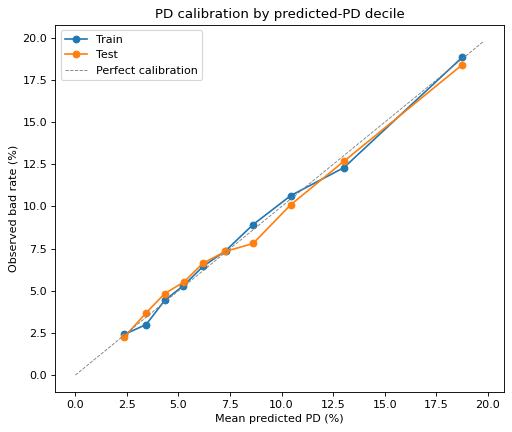

In [5]:
_, pd_edges = pd.qcut(pd_train, q=10, retbins=True)
pd_edges[0], pd_edges[-1] = 0, 1
calibration = []
for sample, p, y in [('Train', pd_train, y_train.values), ('Test', pd_test, y_test.values)]:
    band = pd.cut(p, pd_edges, labels=range(1, 11))
    g = pd.DataFrame({'band': band, 'pd': p, 'y': y}).groupby('band', observed=True).agg(Applicants=('y', 'size'), Mean_PD=('pd', 'mean'), Observed=('y', 'mean'))
    g['Sample'] = sample
    calibration.append(g)
calibration = pd.concat(calibration).reset_index()
calibration_view = calibration.pivot(index='band', columns='Sample', values=['Mean_PD', 'Observed'])
display(calibration_view.style.format('{:.2%}'))
max_gap = (calibration['Mean_PD'] - calibration['Observed']).abs().max()
print(f'Largest gap between mean predicted PD and observed bad rate in any band: {max_gap:.2%}')

fig, ax = plt.subplots(figsize=(6.5, 5.5))
for sample, colour in [('Train', 'tab:blue'), ('Test', 'tab:orange')]:
    s = calibration[calibration['Sample'] == sample]
    ax.plot(s['Mean_PD'] * 100, s['Observed'] * 100, 'o-', color=colour, label=sample)
lim = calibration[['Mean_PD', 'Observed']].max().max() * 100 * 1.05
ax.plot([0, lim], [0, lim], color='grey', linestyle='--', linewidth=0.8, label='Perfect calibration')
ax.set_xlabel('Mean predicted PD (%)'); ax.set_ylabel('Observed bad rate (%)')
ax.set_title('PD calibration by predicted-PD decile'); ax.legend()
plt.tight_layout()
plt.show()

**What we found**

- **The loaded set-up is confirmed:** 11 model characteristics, standard logistic regression, reference scale 600 at 1:11.56 (PDO 20), test AUC 0.670. Score and PD move in opposite directions (rank correlation -0.9996).
- **The PDs are well calibrated by decile:** the mean predicted PD is within 0.81 percentage points of the observed bad rate in every band, on both samples (from about 2.4% in the safest decile to about 18.8% in the riskiest).
- So we can use them for expected credit loss without recalibrating.

## 7.2 Financial Assumptions (editable)

**We do not have the lender's financial data (interest rates, funding cost, operating cost, recoveries).** The values below are therefore **our own illustrative assumptions**, not real bank figures. We kept them simple, and they can be changed in this one cell; every result below is recalculated from them.

| Parameter | How we use it |
|---|---|
| **EAD** (exposure at default) | Each applicant's own loan amount, `AMT_CREDIT`, from `data/merged_data.csv` |
| **Interest and fee revenue** | `INTEREST_FEE_RATE x EAD` over the horizon |
| **Funding cost** | `FUNDING_COST_RATE x EAD` |
| **Operating cost** | `OPERATING_COST_RATE x EAD` (origination and servicing) |
| **LGD** | Share of the exposure lost when a borrower defaults |

**Currency.** The data dictionary does not say what currency `AMT_CREDIT` is in, so we keep amounts in their **source currency units** and label them that way. We do **not** convert them to Singapore dollars. `FX_TO_SGD` can be set once the currency and rate are known.

**Time horizon.** `TARGET` flags payment difficulties on the first instalments of the loan, and our PDs come from a model of that flag. So we apply all rates over **one common horizon**, which we treat as one year: one year of revenue and costs, against the PD for that horizon. A full lifetime pricing model is outside our scope.

For each approved applicant:

- `Expected credit loss = PD x LGD x EAD`
- `Expected net profit = Revenue - Funding cost - Operating cost - Expected credit loss`

Declined applicants make no profit or loss.

In [6]:
# ------------------------- EDITABLE ASSUMPTIONS (illustrative, not actual bank data) -------------------------
CURRENCY_LABEL = 'source currency units'   # currency of AMT_CREDIT is not stated in the data dictionary
FX_TO_SGD = None                           # e.g. set to a confirmed rate to express results in SGD
HORIZON = '1 year'

INTEREST_FEE_RATE = 0.12                   # interest and fee revenue, % of EAD over the horizon
FUNDING_COST_RATE = 0.04                   # cost of funds, % of EAD
OPERATING_COST_RATE = 0.02                 # origination and servicing, % of EAD
LGD = 0.60                                 # loss given default (unsecured lending)

RISK_TOLERANCES = np.round(np.arange(0.02, 0.10 + 1e-9, 0.005), 3)   # max approved-portfolio bad rate: 2% to 10%
# --------------------------------------------------------------------------------------------------------------

unit = 'SGD' if FX_TO_SGD else CURRENCY_LABEL
fx = FX_TO_SGD or 1.0
margin = INTEREST_FEE_RATE - FUNDING_COST_RATE - OPERATING_COST_RATE
BREAK_EVEN_PD = margin / LGD
display(pd.DataFrame({'Value': {
    'Horizon': HORIZON, 'Currency': unit,
    'Interest and fee revenue (% of EAD)': f'{INTEREST_FEE_RATE:.1%}', 'Funding cost (% of EAD)': f'{FUNDING_COST_RATE:.1%}',
    'Operating cost (% of EAD)': f'{OPERATING_COST_RATE:.1%}', 'LGD': f'{LGD:.0%}',
    'Margin before credit losses (% of EAD)': f'{margin:.1%}',
    'Break-even PD (margin / LGD)': f'{BREAK_EVEN_PD:.2%}',
    'Risk tolerances tested': f'{RISK_TOLERANCES.min():.1%} to {RISK_TOLERANCES.max():.1%} in {len(RISK_TOLERANCES)} steps'}}))

,Value
Horizon,1 year
Currency,source currency units
Interest and fee revenue (% of EAD),12.0%
Funding cost (% of EAD),4.0%
Operating cost (% of EAD),2.0%
LGD,60%
Margin before credit losses (% of EAD),6.0%
Break-even PD (margin / LGD),10.00%
Risk tolerances tested,2.0% to 10.0% in 17 steps


In [7]:
# applicant-level exposure: the actual loan amount of each applicant
ead = pd.read_csv('data/merged_data.csv', usecols=[ID, 'AMT_CREDIT']).set_index(ID)['AMT_CREDIT']
for df, p in [(train, pd_train), (test, pd_test)]:
    df['EAD'] = df[ID].map(ead).values * fx
    df['PD'] = p
    df['Revenue'] = INTEREST_FEE_RATE * df['EAD']
    df['Funding cost'] = FUNDING_COST_RATE * df['EAD']
    df['Operating cost'] = OPERATING_COST_RATE * df['EAD']
    df['Expected credit loss'] = df['PD'] * LGD * df['EAD']
    df['Expected net profit'] = df['Revenue'] - df['Funding cost'] - df['Operating cost'] - df['Expected credit loss']
    df['Realised credit loss'] = df[TARGET] * LGD * df['EAD']          # cross-check with observed outcomes
assert train['EAD'].notnull().all() and test['EAD'].notnull().all()
display(train['EAD'].describe().to_frame(f'EAD (train, {unit})').style.format('{:,.0f}'))
print(f'Applicants with positive expected profit if approved (PD below break-even {BREAK_EVEN_PD:.2%}): {(train["Expected net profit"] > 0).mean():.1%} of training applicants')

,"EAD (train, source currency units)"
count,"149,318"
mean,"589,026"
std,"395,754"
min,"45,000"
25%,"270,000"
50%,"508,496"
75%,"808,650"
max,"4,050,000"


Applicants with positive expected profit if approved (PD below break-even 10.00%): 73.3% of training applicants


## 7.3 Net Profit vs Risk Tolerance

**Which sample we choose on.** We have a training and a test sample but no separate validation sample, and we keep the test sample for the final evaluation. So we choose cutoffs on the **training sample**. With 11 coefficients fitted on 149,318 applicants, the in-sample optimism is very small: the train-to-test AUC gap is 0.007. As a robustness check, we repeat the choice with **out-of-fold** PDs, i.e. predictions for each training applicant from a model that did not see that applicant. We only use the test sample afterwards, to confirm the chosen policy.

**Method.** For each maximum risk tolerance from 2% to 10%, the cutoff is the **lowest score at which the approved training applicants have an observed bad rate at or below the tolerance**, i.e. the most approvals the tolerance allows. We then add up revenue, costs, expected credit loss and expected net profit over the approved applicants.

The tolerance limits the **average** bad rate of the approved portfolio. It is not the PD of the marginal applicant at the cutoff, who is always riskier than the approved average.

In [8]:
def cutoff_profit_table(df, score_col='score'):
    # every candidate cutoff: approved = score >= cutoff, sums over approved applicants
    g = df.groupby(score_col).agg(n=(TARGET, 'size'), bads=(TARGET, 'sum'), revenue=('Revenue', 'sum'), funding=('Funding cost', 'sum'),
                                  operating=('Operating cost', 'sum'), ecl=('Expected credit loss', 'sum'),
                                  profit=('Expected net profit', 'sum'), realised_loss=('Realised credit loss', 'sum')).sort_index(ascending=False)
    cum = g.cumsum()
    t = pd.DataFrame({'Cutoff': cum.index, 'Approved applicants': cum['n'].values, 'Approval rate': cum['n'].values / len(df),
                      'Bads approved': cum['bads'].values, 'Approved bad rate': cum['bads'].values / cum['n'].values,
                      'Revenue': cum['revenue'].values, 'Funding cost': cum['funding'].values, 'Operating cost': cum['operating'].values,
                      'Expected credit loss': cum['ecl'].values, 'Expected net profit': cum['profit'].values,
                      'Realised net profit': (cum['revenue'] - cum['funding'] - cum['operating'] - cum['realised_loss']).values})
    return t.sort_values('Cutoff').reset_index(drop=True)


def tolerance_table(cutoffs, tolerances):
    rows = []
    for tol in tolerances:
        eligible = cutoffs[cutoffs['Approved bad rate'] <= tol + 1e-12]
        if eligible.empty:
            rows.append({'Maximum risk %': tol, 'Score cutoff': np.nan, 'Note': 'No cutoff meets this tolerance'})
            continue
        r = eligible.loc[eligible['Cutoff'].idxmin()]
        note = 'All applicants approved (tolerance above portfolio bad rate)' if r['Cutoff'] == cutoffs['Cutoff'].min() else ''
        rows.append({'Maximum risk %': tol, 'Actual approved bad rate': r['Approved bad rate'], 'Score cutoff': r['Cutoff'],
                     'Approval rate': r['Approval rate'], 'Approved applicants': r['Approved applicants'],
                     'Expected credit loss': r['Expected credit loss'], 'Expected net profit': r['Expected net profit'],
                     'Realised net profit': r['Realised net profit'], 'Note': note})
    return pd.DataFrame(rows)


cutoffs_train = cutoff_profit_table(train)

sensitivity = tolerance_table(cutoffs_train, RISK_TOLERANCES)
# tolerances that lead to the same cutoff are the same lending decision
sensitivity['Same decision as'] = sensitivity.groupby('Score cutoff')['Maximum risk %'].transform('min').map(lambda v: f'{v:.1%}')

money = '{:,.0f}'
display(sensitivity.style.format({'Maximum risk %': '{:.1%}', 'Actual approved bad rate': '{:.2%}', 'Score cutoff': '{:.0f}', 'Approval rate': '{:.1%}',
                                  'Approved applicants': '{:,.0f}', 'Expected credit loss': money, 'Expected net profit': money,
                                  'Realised net profit': money}, na_rep='-').hide(axis='index'))
print(f'Amounts in {unit}, {HORIZON} horizon, training sample.')

Maximum risk %,Actual approved bad rate,Score cutoff,Approval rate,Approved applicants,Expected credit loss,Expected net profit,Realised net profit,Note,Same decision as
2.0%,1.98%,641,2.6%,"3,933","30,564,464","138,929,186","134,709,906",,2.0%
2.5%,2.44%,630,11.9%,"17,719","169,683,261","521,485,252","523,092,946",,2.5%
3.0%,3.00%,620,25.1%,"37,421","451,964,674","992,089,279","1,011,545,252",,3.0%
3.5%,3.48%,615,33.6%,"50,114","674,265,206","1,241,861,454","1,261,973,266",,3.5%
4.0%,3.92%,610,42.6%,"63,614","946,906,485","1,462,189,845","1,480,770,720",,4.0%
4.5%,4.47%,605,53.3%,"79,608","1,308,501,770","1,659,485,458","1,671,352,812",,4.5%
5.0%,4.88%,601,61.0%,"91,108","1,612,210,618","1,759,523,644","1,760,896,310",,5.0%
5.5%,5.48%,595,70.8%,"105,709","2,057,259,344","1,824,348,853","1,810,374,320",,5.5%
6.0%,5.97%,590,78.4%,"117,032","2,445,018,474","1,811,575,082","1,790,284,585",,6.0%
6.5%,6.47%,584,86.2%,"128,650","2,904,806,395","1,729,990,807","1,745,300,284",,6.5%


Amounts in source currency units, 1 year horizon, training sample.


Highest expected profit on the tolerance grid: tolerance 5.5% -> cutoff 595 (interior of the tested range)
Most profitable of all integer cutoffs: 593 with expected profit 1,826,164,192 vs 1,824,348,853 on the grid (source currency units)


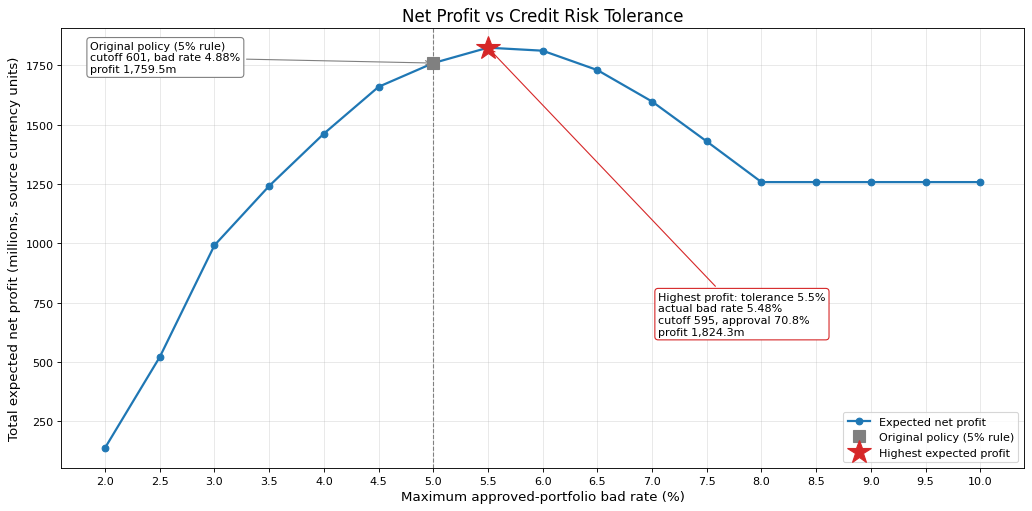

In [9]:
# profit-maximising policy among the tested risk tolerances (ties = the same cutoff, keep the lowest tolerance)
evaluated = sensitivity.dropna(subset=['Score cutoff'])
best = evaluated.loc[evaluated['Expected net profit'].idxmax()]
OPT_TOLERANCE, OPT_CUTOFF = float(best['Maximum risk %']), int(best['Score cutoff'])

CURRENT_TOLERANCE = TARGET_BAD_RATE                                   # the original policy rule (5%)
RULE5_CUTOFF = int(sensitivity.loc[np.isclose(sensitivity['Maximum risk %'], CURRENT_TOLERANCE), 'Score cutoff'].iloc[0])
current = cutoffs_train.set_index('Cutoff').loc[RULE5_CUTOFF]         # the original policy

# check: the most profitable of ALL integer cutoffs (not only those produced by the tolerance grid)
free_best = cutoffs_train.loc[cutoffs_train['Expected net profit'].idxmax()]
at_boundary = OPT_TOLERANCE in (evaluated['Maximum risk %'].min(), evaluated['Maximum risk %'].max())
print(f'Highest expected profit on the tolerance grid: tolerance {OPT_TOLERANCE:.1%} -> cutoff {OPT_CUTOFF}'
      f'{" (at the boundary of the tested range)" if at_boundary else " (interior of the tested range)"}')
print(f'Most profitable of all integer cutoffs: {free_best["Cutoff"]:.0f} with expected profit {free_best["Expected net profit"]:,.0f} '
      f'vs {best["Expected net profit"]:,.0f} on the grid ({unit})')

# --------------------------------------------- the sensitivity graph ---------------------------------------------
scale = 1e6
fig, ax = plt.subplots(figsize=(13, 6.5))
ax.plot(evaluated['Maximum risk %'] * 100, evaluated['Expected net profit'] / scale, '-o', color='tab:blue', linewidth=2, markersize=6,
        label='Expected net profit')
ax.axvline(CURRENT_TOLERANCE * 100, color='grey', linestyle='--', linewidth=1)
cur_row = evaluated.loc[np.isclose(evaluated['Maximum risk %'], CURRENT_TOLERANCE)].iloc[0]
ax.plot(CURRENT_TOLERANCE * 100, cur_row['Expected net profit'] / scale, 's', color='grey', markersize=11, label='Original policy (5% rule)')
ax.annotate(f"Original policy (5% rule)\ncutoff {RULE5_CUTOFF}, bad rate {current['Approved bad rate']:.2%}\n"
            f"profit {current['Expected net profit'] / scale:,.1f}m",
            xy=(CURRENT_TOLERANCE * 100, cur_row['Expected net profit'] / scale), xytext=(0.03, 0.97), textcoords='axes fraction', va='top',
            fontsize=10, arrowprops=dict(arrowstyle='->', color='grey'), bbox=dict(boxstyle='round', fc='white', ec='grey'))
ax.plot(OPT_TOLERANCE * 100, best['Expected net profit'] / scale, '*', color='tab:red', markersize=22, label='Highest expected profit', zorder=5)
ax.annotate(f"Highest profit: tolerance {OPT_TOLERANCE:.1%}\nactual bad rate {best['Actual approved bad rate']:.2%}\n"
            f"cutoff {OPT_CUTOFF}, approval {best['Approval rate']:.1%}\nprofit {best['Expected net profit'] / scale:,.1f}m",
            xy=(OPT_TOLERANCE * 100, best['Expected net profit'] / scale), xytext=(0.62, 0.40), textcoords='axes fraction', va='top',
            fontsize=10, arrowprops=dict(arrowstyle='->', color='tab:red'), bbox=dict(boxstyle='round', fc='white', ec='tab:red'))
ax.set_title('Net Profit vs Credit Risk Tolerance', fontsize=15)
ax.set_xlabel('Maximum approved-portfolio bad rate (%)', fontsize=12)
ax.set_ylabel(f'Total expected net profit (millions, {unit})', fontsize=12)
ax.set_xticks(evaluated['Maximum risk %'] * 100)
ax.tick_params(labelsize=10)
ax.grid(alpha=0.3)
ax.legend(loc='lower right', fontsize=10)
plt.tight_layout()
plt.show()

In [10]:
# explanation generated from the results, so it stays correct if the assumptions are edited
up = evaluated[evaluated['Maximum risk %'] <= OPT_TOLERANCE]
down = evaluated[evaluated['Maximum risk %'] >= OPT_TOLERANCE]
marginal = cutoffs_train[(cutoffs_train['Cutoff'] == OPT_CUTOFF - 1)]
at_cut_pd = train.loc[train['score'] == OPT_CUTOFF, 'PD'].mean()
below_pd = train.loc[train['score'] == OPT_CUTOFF - 1, 'PD'].mean()
change = best['Expected net profit'] - current['Expected net profit']
display(Markdown(f'''
**Interpretation (calculated from the current assumptions)**

- **Why the curve rises, then falls.** Raising the tolerance lowers the cutoff and admits riskier applicants. Each extra loan earns a margin of {margin:.1%} of its amount before losses, and is expected to lose `PD x {LGD:.0%}` of it. While the extra applicants' PD is below the break-even PD of **{BREAK_EVEN_PD:.2%}**, each adds profit; beyond it, each extra loan destroys value.
- **Where the maximum is.** Expected net profit peaks at a tolerance of **{OPT_TOLERANCE:.1%}**: cutoff **{OPT_CUTOFF}**, approval rate {best['Approval rate']:.1%}, actual approved bad rate {best['Actual approved bad rate']:.2%}, expected profit {best['Expected net profit']:,.0f} {unit}.{' This is at the boundary of the tested range, so the true optimum may lie outside it.' if at_boundary else ' This is an interior point of the tested range.'}
- **The marginal applicant.** Applicants scoring exactly {OPT_CUTOFF} have an average PD of {at_cut_pd:.2%}, and those one point lower {below_pd:.2%}, around the break-even PD. The approved portfolio's average bad rate ({best['Actual approved bad rate']:.2%}) is much lower, because it averages over all the safer applicants above the cutoff.
- **Compared with the original policy.** The 5% rule gives cutoff {RULE5_CUTOFF} (approval {current['Approval rate']:.1%}) and is expected to earn {current['Expected net profit']:,.0f}; the profit-maximising policy changes this by **{change:+,.0f} {unit}** ({change / current['Expected net profit']:+.1%}).
- **Grid vs free search.** The best of all integer cutoffs is {free_best['Cutoff']:.0f} ({free_best['Expected net profit']:,.0f}), so the 0.5-point tolerance grid {'finds the same decision' if int(free_best['Cutoff']) == OPT_CUTOFF else 'lands close to it'}.
- **Several tolerances can give the same cutoff:** once the tolerance exceeds the portfolio bad rate (7.96%), every applicant is approved, so those points are one decision. The `Same decision as` column marks this.
'''))


**Interpretation (calculated from the current assumptions)**

- **Why the curve rises, then falls.** Raising the tolerance lowers the cutoff and admits riskier applicants. Each extra loan earns a margin of 6.0% of its amount before losses, and is expected to lose `PD x 60%` of it. While the extra applicants' PD is below the break-even PD of **10.00%**, each adds profit; beyond it, each extra loan destroys value.
- **Where the maximum is.** Expected net profit peaks at a tolerance of **5.5%**: cutoff **595**, approval rate 70.8%, actual approved bad rate 5.48%, expected profit 1,824,348,853 source currency units. This is an interior point of the tested range.
- **The marginal applicant.** Applicants scoring exactly 595 have an average PD of 9.45%, and those one point lower 9.77%, around the break-even PD. The approved portfolio's average bad rate (5.48%) is much lower, because it averages over all the safer applicants above the cutoff.
- **Compared with the original policy.** The 5% rule gives cutoff 601 (approval 61.0%) and is expected to earn 1,759,523,644; the profit-maximising policy changes this by **+64,825,208 source currency units** (+3.7%).
- **Grid vs free search.** The best of all integer cutoffs is 593 (1,826,164,192), so the 0.5-point tolerance grid lands close to it.
- **Several tolerances can give the same cutoff:** once the tolerance exceeds the portfolio bad rate (7.96%), every applicant is approved, so those points are one decision. The `Same decision as` column marks this.


### Robustness check: out-of-fold PDs (training sample)

The in-sample PDs come from a model that saw every training applicant. Here each training applicant gets a PD from a 5-fold model that did **not** see them. We use the same set-up, and these refits are only for this check; the scorecard model does not change. We convert the out-of-fold PDs to unrounded scores on the current scale and repeat the tolerance analysis.

In [11]:
oof_pd = cross_val_predict(linear_model.LogisticRegression(**configs[LR_CONFIG]), X_train, y_train, cv=cv, method='predict_proba')[:, 1]
oof = train[[TARGET, 'EAD', 'Revenue', 'Funding cost', 'Operating cost']].copy()
oof['score'] = np.round(OFFSET - FACTOR * np.log(oof_pd / (1 - oof_pd)))
oof['Expected credit loss'] = oof_pd * LGD * oof['EAD']
oof['Expected net profit'] = oof['Revenue'] - oof['Funding cost'] - oof['Operating cost'] - oof['Expected credit loss']
oof['Realised credit loss'] = oof[TARGET] * LGD * oof['EAD']
sensitivity_oof = tolerance_table(cutoff_profit_table(oof), RISK_TOLERANCES).dropna(subset=['Score cutoff'])
best_oof = sensitivity_oof.loc[sensitivity_oof['Expected net profit'].idxmax()]

robust = pd.DataFrame({
    'In-sample PDs (used)': {'Profit-maximising tolerance': f'{OPT_TOLERANCE:.1%}', 'Cutoff': OPT_CUTOFF,
                             'Approval rate': f'{best["Approval rate"]:.1%}', 'Approved bad rate': f'{best["Actual approved bad rate"]:.2%}'},
    'Out-of-fold PDs': {'Profit-maximising tolerance': f'{best_oof["Maximum risk %"]:.1%}', 'Cutoff': int(best_oof['Score cutoff']),
                        'Approval rate': f'{best_oof["Approval rate"]:.1%}', 'Approved bad rate': f'{best_oof["Actual approved bad rate"]:.2%}'}})
display(robust)
print(f'Out-of-fold AUC (train): {metrics.roc_auc_score(y_train, oof_pd):.4f} vs in-sample {metrics.roc_auc_score(y_train, pd_train):.4f}')

,In-sample PDs (used),Out-of-fold PDs
Profit-maximising tolerance,5.5%,5.5%
Cutoff,595,595
Approval rate,70.8%,70.1%
Approved bad rate,5.48%,5.44%


Out-of-fold AUC (train): 0.6765 vs in-sample 0.6770


## 7.4 Profit-Maximising Policy vs Original Policy

We did not use the test sample to choose the cutoff. We show it here only to confirm that the chosen policy behaves the same way on unseen applicants.

In [12]:
cutoffs_test = cutoff_profit_table(test)
def policy(cutoffs, c):
    # metrics at cutoff c (if c is not an observed score, use the next observed score above it)
    return cutoffs[cutoffs['Cutoff'] >= c].iloc[0]

def new_policy(df, cutoffs, c):
    r = policy(cutoffs, c)
    a = df['score'] >= c
    return {'Approved applicants': int(r['Approved applicants']), 'Approval rate': r['Approval rate'], 'Approved bad rate': r['Approved bad rate'],
            'Expected portfolio default rate': df.loc[a, 'PD'].mean(), 'Expected credit loss': r['Expected credit loss'],
            'Expected net profit': r['Expected net profit'], 'Realised net profit': r['Realised net profit']}

columns = {'Original policy (5% rule)': (f'{CURRENT_TOLERANCE:.1%}', RULE5_CUTOFF,
                                         new_policy(train, cutoffs_train, RULE5_CUTOFF), new_policy(test, cutoffs_test, RULE5_CUTOFF)),
           'Profit-maximising policy': (f'{OPT_TOLERANCE:.1%}', OPT_CUTOFF,
                                        new_policy(train, cutoffs_train, OPT_CUTOFF), new_policy(test, cutoffs_test, OPT_CUTOFF))}
columns = {k: (len(MODEL_X),) + v for k, v in columns.items()}
comparison = pd.DataFrame({name: {
    'Model characteristics': n, 'Risk tolerance': tol, 'Approval cutoff (reference scale)': c,
    'Approval rate (train)': f"{tr_['Approval rate']:.1%}", 'Approved applicants (train)': f"{tr_['Approved applicants']:,}",
    'Observed approved bad rate (train)': f"{tr_['Approved bad rate']:.2%}",
    'Expected portfolio default rate (mean PD of approved, train)': f"{tr_['Expected portfolio default rate']:.2%}",
    f'Expected credit loss (train, {unit})': f"{tr_['Expected credit loss']:,.0f}",
    f'Expected net profit (train, {unit})': f"{tr_['Expected net profit']:,.0f}",
    f'Realised net profit (train, observed defaults, {unit})': f"{tr_['Realised net profit']:,.0f}",
    'Approval rate / approved bad rate (test, confirmation only)': f"{te_['Approval rate']:.1%} / {te_['Approved bad rate']:.2%}",
    f'Expected net profit (test, {unit})': f"{te_['Expected net profit']:,.0f}"} for name, (n, tol, c, tr_, te_) in columns.items()})
display(comparison)

orig_train, orig_test = columns['Original policy (5% rule)'][3], columns['Original policy (5% rule)'][4]
opt_train, opt_test = columns['Profit-maximising policy'][3], columns['Profit-maximising policy'][4]
delta_train = opt_train['Expected net profit'] - orig_train['Expected net profit']
delta_test = opt_test['Expected net profit'] - orig_test['Expected net profit']
realised_policy = opt_train['Realised net profit'] - orig_train['Realised net profit']
print(f'Change in expected net profit vs the original policy: {delta_train:+,.0f} (train), {delta_test:+,.0f} (test) {unit}')
print(f'Change in realised net profit (observed defaults, train): {realised_policy:+,.0f} {unit}')

# supplementary diagnostics (not the selection criterion)
diag = {}
for name, c in [('Original policy (5% rule)', RULE5_CUTOFF), ('Profit-maximising policy', OPT_CUTOFF)]:
    pb = train['score'] < c
    tp, fp = (pb & (train[TARGET] == 1)).sum(), (pb & (train[TARGET] == 0)).sum()
    fn, tn = (~pb & (train[TARGET] == 1)).sum(), (~pb & (train[TARGET] == 0)).sum()
    prec, rec = tp / (tp + fp), tp / (tp + fn)
    diag[name] = {'Recall (bad)': rec, 'Specificity': tn / (tn + fp), 'Precision (bad)': prec, 'F1 (bad)': 2 * prec * rec / (prec + rec)}
display(pd.DataFrame(diag).style.format('{:.4f}'))

,Original policy (5% rule),Profit-maximising policy
Model characteristics,11,11
Risk tolerance,5.0%,5.5%
Approval cutoff (reference scale),601,595
Approval rate (train),61.0%,70.8%
Approved applicants (train),"91,108","105,709"
Observed approved bad rate (train),4.88%,5.48%
"Expected portfolio default rate (mean PD of approved, train)",4.86%,5.39%
"Expected credit loss (train, source currency units)","1,612,210,618","2,057,259,344"
"Expected net profit (train, source currency units)","1,759,523,644","1,824,348,853"
"Realised net profit (train, observed defaults, source currency units)","1,760,896,310","1,810,374,320"


Change in expected net profit vs the original policy: +64,825,208 (train), +26,817,342 (test) source currency units
Change in realised net profit (observed defaults, train): +49,478,009 source currency units


,Original policy (5% rule),Profit-maximising policy
Recall (bad),0.6260,0.5130
Specificity,0.6306,0.7271
Precision (bad),0.1278,0.1398
F1 (bad),0.2123,0.2198


**What we found (default assumptions)**

- **The profit-maximising policy uses a 5.5% tolerance: cutoff 595 on the reference scale.**
  - It approves 70.8% of training applicants, with an observed bad rate of 5.48%.
  - The out-of-fold PDs pick the same cutoff.
  - Searching every whole-number cutoff finds 593, worth only 0.1% more, so our grid choice is effectively the best.
- **Compared with the original 5% policy** (cutoff 601, 61.0% approved, 4.88% bad rate):
  - expected net profit rises by about **64.8 million** (+3.7%) on the training sample and 26.8 million on test
  - realised profit, using actual defaults, rises by about **49.5 million**
- **Why it pays.** The extra applicants we approve have PDs between about 7.7% (the original cutoff) and 9.3%, below the 10% break-even PD, so each one adds more expected margin than expected loss.
- **The trade-off:** recall of bad borrowers falls from 0.63 to 0.51, and specificity rises from 0.63 to 0.73. We did not choose on F1; 7.7 looks at it in full.

## 7.5 Aligning the Score Scale with the Chosen Cutoff

Choosing a more profitable cutoff is the **business** decision. Rescaling only changes how scores are **presented**. It does not change the model, the ranking of applicants, the AUC or the expected profit, as long as the same applicants are approved.

### 7.5.1 Odds at the profit-maximising cutoff

Scores are whole numbers, so approving `score >= cutoff` is the same as approving an **unrounded** score of at least `cutoff - 0.5`. We therefore anchor the new scale at the odds of the cutoff score itself: the unrounded boundary (`cutoff - 0.5`) then lands at 599.5 on the new scale, and the whole-number rule **score >= 600** gives exactly the same decisions, before point rounding.

Each of the 11 characteristics' points is rounded to a whole number, so an applicant's rounded total can be a few points off the unrounded score. In 7.5.2 we measure how many decisions this changes for each option.

In [13]:
# whole-number scores: 'score >= OPT_CUTOFF' is the unrounded boundary OPT_CUTOFF - 0.5
DECISION_BOUNDARY = OPT_CUTOFF - 0.5
ODDS_AT_OPT = np.exp((OFFSET - OPT_CUTOFF) / FACTOR)            # odds implied by the reference scale at the cutoff score
ODDS_AT_BOUNDARY = np.exp((OFFSET - DECISION_BOUNDARY) / FACTOR)   # odds at the unrounded decision boundary
marginal_pd = train.loc[train['score'] == OPT_CUTOFF, 'PD']
display(pd.DataFrame({'Value': {
    'Profit-maximising cutoff (reference scale)': OPT_CUTOFF,
    'Unrounded decision boundary (reference scale)': DECISION_BOUNDARY,
    'Model-implied bad:good odds at the cutoff score': f'{ODDS_AT_OPT:.5f} = 1 : {1 / ODDS_AT_OPT:.2f}',
    'Model-implied PD at the cutoff score': f'{ODDS_AT_OPT / (1 + ODDS_AT_OPT):.2%}',
    'Mean model PD of applicants scoring exactly at the cutoff (unrounded)': f'{marginal_pd.mean():.2%} ({len(marginal_pd):,} applicants)',
    'Break-even PD under the assumptions': f'{BREAK_EVEN_PD:.2%}',
    'Observed bad rate of ALL approved applicants': f'{policy(cutoffs_train, OPT_CUTOFF)["Approved bad rate"]:.2%}',
}}))

,Value
Profit-maximising cutoff (reference scale),595
Unrounded decision boundary (reference scale),594.5
Model-implied bad:good odds at the cutoff score,0.10287 = 1 : 9.72
Model-implied PD at the cutoff score,9.33%
Mean model PD of applicants scoring exactly at the cutoff (unrounded),"9.45% (2,454 applicants)"
Break-even PD under the assumptions,10.00%
Observed bad rate of ALL approved applicants,5.48%


### 7.5.2 Candidate scaling configurations

We compare three options. Each keeps the same bins and model and is generated with `sc.scorecard`; none of them replaces the reference-scale scorecard here.

| Option | Idea |
|---|---|
| **Reference** | 600 at the training sample's own odds, PDO 20 (Step 6); the profit-maximising cutoff would be used at its reference-scale value |
| **Option A** | 600 at the odds of our chosen cutoff, PDO 20: the cutoff moves to 600 and the score spread stays the same |
| **Option B** | 600 at the odds of our chosen cutoff, PDO 10: also moves the cutoff to 600, but halves the spread |

PDO does not affect accuracy. It sets how many points equal a doubling of the odds, and so how fine the score is. Because each characteristic's points are rounded to whole numbers, a smaller PDO means a coarser score: more applicants near the cutoff can switch decision just from rounding. The agreement check below measures this.

In [14]:
SCALING_OPTIONS = {'Reference': (POINTS0, ODDS0_REFERENCE, PDO),
                   'Proposed A': (600, ODDS_AT_OPT, 20),
                   'Proposed B': (600, ODDS_AT_OPT, 10)}

# reference decision = the chosen policy on UNROUNDED model scores (no point rounding):
# approve if the unrounded reference-scale score is at least OPT_CUTOFF - 0.5
unrounded_current = OFFSET - FACTOR * np.log(pd_train / (1 - pd_train))
reference_decision = unrounded_current >= DECISION_BOUNDARY
rounded_current_decision = (train['score'] >= OPT_CUTOFF).values

scaling_rows, option_scores, option_cutoffs = {}, {}, {}
for name, (p0, o0, pdo_) in SCALING_OPTIONS.items():
    factor_ = pdo_ / np.log(2)
    offset_ = p0 + factor_ * np.log(o0)
    card_ = card if name == 'Reference' else sc.scorecard(bins, lr, X_train.columns, points0=p0, odds0=o0, pdo=pdo_, basepoints_eq0=True)
    s_ = sc.scorecard_ply(train[MODEL_X], card_)['score'].values
    # operating cutoff: the whole number whose rule 'score >= cutoff' maps onto the unrounded decision boundary
    mapped = offset_ - factor_ * np.log(ODDS_AT_BOUNDARY)          # the unrounded decision boundary on this scale
    cut = int(np.round(mapped + 0.5))                              # 'score >= cut' <=> unrounded score >= cut - 0.5
    diffs = {cut: int(((s_ >= cut) != reference_decision).sum())}
    option_scores[name], option_cutoffs[name] = s_, cut
    vs_current = int(((s_ >= cut) != rounded_current_decision).sum())
    scaling_rows[name] = {'Target score': p0, 'Target odds (bad:good)': f'1 : {1 / o0:.2f}', 'PDO': pdo_,
                          'Factor': round(factor_, 3), 'Offset': round(offset_, 2),
                          'Decision boundary on this scale (unrounded)': round(mapped, 2), 'Operating cutoff (score >= cutoff)': cut,
                          'Score range (train, min - max)': f'{s_.min():.0f} - {s_.max():.0f}',
                          'Score range (train, 1st - 99th pct)': f'{np.percentile(s_, 1):.0f} - {np.percentile(s_, 99):.0f}',
                          'Score std (train)': round(s_.std(), 1),
                          'Decisions differing from the unrounded policy': f'{diffs[cut]:,} ({diffs[cut] / len(train):.2%})',
                          f'Decisions differing from the reference-scale scorecard at {OPT_CUTOFF}': f'{vs_current:,} ({vs_current / len(train):.2%})'}
scaling_comparison = pd.DataFrame(scaling_rows)
display(scaling_comparison)

# recommendation rule: among the options that put the cutoff at the target score, prefer fewer rounding-induced differences
aligned = {k: int(v['Decisions differing from the unrounded policy'].split(' ')[0].replace(',', ''))
           for k, v in scaling_rows.items() if k != 'Reference' and v['Operating cutoff (score >= cutoff)'] == v['Target score']}
RECOMMENDED_SCALING = min(aligned, key=aligned.get) if aligned else 'Reference'
print('Recommended configuration:', RECOMMENDED_SCALING)

,Reference,Proposed A,Proposed B
Target score,600,600,600
Target odds (bad:good),1 : 11.56,1 : 9.72,1 : 9.72
PDO,20,20,10
Factor,28.854,28.854,14.427
Offset,529.38,534.38,567.19
Decision boundary on this scale (unrounded),594.5,599.5,599.75
Operating cutoff (score >= cutoff),595,600,600
"Score range (train, min - max)",543 - 664,546 - 665,573 - 633
"Score range (train, 1st - 99th pct)",563 - 647,567 - 650,583 - 625
Score std (train),19.2,18.9,9.4


Recommended configuration: Proposed A


**What we found**

- **Anchoring.** The model's odds at our chosen cutoff (595 on the reference scale) are **1:9.72**, a PD of 9.33%, just below the 10% break-even PD. Applicants scoring exactly 595 have an average model PD of 9.45%.
- **We recommend Option A: 600 at 1:9.72, PDO 20, approve if score >= 600.**
  - The approval line reads as 600, which is easy to explain.
  - The score spread is unchanged (about 546-665, standard deviation 19).
- **Rounding.** It differs from the unrounded policy for 1.39% of applicants, against 0.82% on the reference scale, because each of the 11 characteristics' points is rounded separately on each scale.
- **We do not recommend Option B (PDO 10).** It halves the spread and raises the rounding differences to 2.02%.
- **Rescaling adds no predictive power.** It only changes the printed points. The model, ranking, PDs, AUC and economics are the ones we chose in 7.4.

## 7.6 Final Rescaling

Up to here we have only **compared** policies and scales. The reference-scale scorecard (`card`) stays as it is, and no final scores exist, until we switch the final scale on.

The settings below can be edited. They default to the option we recommended above; nothing in them is typed in by hand. We agreed Option A as a team on 2026-10-30, so `FINAL_SCALING_APPROVED` is set to `True` and the final scorecard is generated.

In [15]:
# ------------------------- FINAL SCALING CONFIGURATION (editable) -------------------------
FINAL_POINTS0, FINAL_ODDS0, FINAL_PDO = SCALING_OPTIONS[RECOMMENDED_SCALING]
FINAL_CUTOFF = option_cutoffs[RECOMMENDED_SCALING]
FINAL_SCALING_APPROVED = True           # agreed as a team on 2026-10-30 (600 at the cutoff odds, PDO 20, cutoff 600)
# -------------------------------------------------------------------------------------------

decision_summary = pd.DataFrame({'Proposed value': {
    'Profit-maximising risk tolerance': f'{OPT_TOLERANCE:.1%}',
    'Optimal cutoff (reference scale)': OPT_CUTOFF,
    f'Expected net profit (train, {unit})': f'{best["Expected net profit"]:,.0f}',
    'Approval rate / approved bad rate (train)': f'{best["Approval rate"]:.1%} / {best["Actual approved bad rate"]:.2%}',
    'Proposed target score': FINAL_POINTS0,
    'Proposed target odds (bad:good)': f'1 : {1 / FINAL_ODDS0:.2f}',
    'Proposed PDO': FINAL_PDO,
    'Rescaled cutoff': FINAL_CUTOFF,
    'FINAL_SCALING_APPROVED': FINAL_SCALING_APPROVED,
}})
display(decision_summary)

odds_rule = np.exp((OFFSET - RULE5_CUTOFF) / FACTOR)       # model-implied odds at the original policy's cutoff
display(pd.DataFrame({
    'Original policy (reference scale, 5% rule)': {
        'Target score': POINTS0, 'Target odds (bad:good)': f'1 : {1 / ODDS0_REFERENCE:.2f}', 'PDO': PDO, 'Operating cutoff': RULE5_CUTOFF,
        'Model-implied PD at cutoff': f'{odds_rule / (1 + odds_rule):.2%}',
        'Expected approved bad rate (mean PD, train)': f"{orig_train['Expected portfolio default rate']:.2%}",
        f'Expected net profit (train, {unit})': f"{orig_train['Expected net profit']:,.0f}"},
    'Profit-based final scorecard (proposed)': {
        'Target score': FINAL_POINTS0, 'Target odds (bad:good)': f'1 : {1 / FINAL_ODDS0:.2f}', 'PDO': FINAL_PDO, 'Operating cutoff': FINAL_CUTOFF,
        'Model-implied PD at cutoff': f'{ODDS_AT_OPT / (1 + ODDS_AT_OPT):.2%}',
        'Expected approved bad rate (mean PD, train)': f"{opt_train['Expected portfolio default rate']:.2%}",
        f'Expected net profit (train, {unit})': f"{opt_train['Expected net profit']:,.0f}"}}))

,Proposed value
Profit-maximising risk tolerance,5.5%
Optimal cutoff (reference scale),595
"Expected net profit (train, source currency units)","1,824,348,853"
Approval rate / approved bad rate (train),70.8% / 5.48%
Proposed target score,600
Proposed target odds (bad:good),1 : 9.72
Proposed PDO,20
Rescaled cutoff,600
FINAL_SCALING_APPROVED,True


,"Original policy (reference scale, 5% rule)",Profit-based final scorecard (proposed)
Target score,600,600
Target odds (bad:good),1 : 11.56,1 : 9.72
PDO,20,20
Operating cutoff,601,600
Model-implied PD at cutoff,7.71%,9.33%
"Expected approved bad rate (mean PD, train)",4.86%,5.39%
"Expected net profit (train, source currency units)","1,759,523,644","1,824,348,853"


### Final scorecard generation

This cell:

1. builds the final scorecard with `sc.scorecard` (same bins, same model)
2. scores both samples with `sc.scorecard_ply`
3. shows the full points table
4. checks that the new cutoff gives the same lending decisions, counting any changes caused by rounding at the boundary
5. confirms that the coefficients, WOE groups, PDs, ranking and AUC are unchanged

Rule: **approve if final score >= final cutoff.** We keep the reference-scale scorecard (`card`) for comparison.

In [16]:
if FINAL_SCALING_APPROVED:
    card_final = sc.scorecard(bins, lr, X_train.columns, points0=FINAL_POINTS0, odds0=FINAL_ODDS0, pdo=FINAL_PDO, basepoints_eq0=True)
    FINAL_FACTOR = FINAL_PDO / np.log(2)
    FINAL_OFFSET = FINAL_POINTS0 + FINAL_FACTOR * np.log(FINAL_ODDS0)
    FINAL_BASE = FINAL_OFFSET - FINAL_FACTOR * lr.intercept_[0]

    final_table = full_scorecard(card_final)
    derived = final_table.apply(lambda r: np.round(-FINAL_FACTOR * coef_by_var[r['Characteristic']] * r['WOE (scorecardpy)'] + FINAL_BASE / len(MODEL_X)), axis=1)
    assert (derived == final_table['Points']).all()
    print(f'Every final point equals round(-Factor x coefficient x WOE + base points / {len(MODEL_X)}): True')
    display(final_table.style.format(card_fmt).hide(axis='index'))

    for df in (train, test):
        df['final_score'] = sc.scorecard_ply(df[MODEL_X], card_final)['score'].values

    # reference-scale vs final decisions (same profit-maximising policy)
    checks_final = {}
    for sample, df in [('Train', train), ('Test', test)]:
        old, new = df['score'] >= OPT_CUTOFF, df['final_score'] >= FINAL_CUTOFF
        display(Markdown(f'**{sample}: approve/decline, reference-scale scorecard at {OPT_CUTOFF} (rows) vs final scorecard at {FINAL_CUTOFF} (columns)**'))
        display(pd.crosstab(old.map({True: 'Approve', False: 'Decline'}), new.map({True: 'Approve', False: 'Decline'})))
        p_ = lr.predict_proba(X_train if sample == 'Train' else X_test)[:, 1]
        ref = (OFFSET - FACTOR * np.log(p_ / (1 - p_))) >= DECISION_BOUNDARY
        checks_final[f'{sample}: decisions differing, final vs reference-scale scorecard (rounding)'] = f'{int((old != new).sum()):,} ({(old != new).mean():.2%})'
        checks_final[f'{sample}: decisions differing from the unrounded policy (current / final)'] = f'{int((old != ref).sum()):,} / {int((new != ref).sum()):,}'
        checks_final[f'{sample}: approval rate / approved bad rate (final)'] = f'{new.mean():.1%} / {df.loc[new, TARGET].mean():.2%}'
        checks_final[f'{sample}: ROC AUC on final score vs current score'] = f'{metrics.roc_auc_score(df[TARGET], -df["final_score"]):.4f} vs {metrics.roc_auc_score(df[TARGET], -df["score"]):.4f}'
        checks_final[f'{sample}: rank correlation final vs current score'] = f'{pd.Series(df["final_score"].values).corr(pd.Series(df["score"].values), method="spearman"):.4f}'
    checks_final['Logistic regression coefficients unchanged'] = bool(np.allclose(np.concatenate([lr.intercept_, lr.coef_[0]]), coefficients.values))
    checks_final['WOE groups unchanged (same IV as Step 5)'] = bool(all(np.isclose(bins[v]['total_iv'].iloc[0], approved_bins['coarse_iv'][v], atol=1e-6) for v in MODEL_X))
    checks_final['Predicted PDs unchanged (same model)'] = bool(np.allclose(lr.predict_proba(X_train)[:, 1], pd_train))
    checks_final['Final score at the reference odds equals the target score'] = bool(np.isclose(FINAL_OFFSET - FINAL_FACTOR * np.log(FINAL_ODDS0), FINAL_POINTS0))
    checks_final['Higher final score = lower PD (Spearman, train)'] = f"{pd.Series(train['final_score'].values).corr(pd.Series(pd_train), method='spearman'):.4f}"
    display(pd.DataFrame({'Result': checks_final}))

    # save the final scorecard results; the reference-scale scorecard (card) is kept in memory for comparison
    final_table.to_csv('data/final_scorecard_points.csv', index=False)
    pd.concat([train[[ID, TARGET, 'final_score']].assign(DATA_SPLIT='TRAIN'), test[[ID, TARGET, 'final_score']].assign(DATA_SPLIT='TEST')])         .assign(DECISION=lambda d: np.where(d['final_score'] >= FINAL_CUTOFF, 'APPROVE', 'DECLINE')).sort_values(ID)         .to_csv('data/final_scores.csv', index=False)
    print('Saved data/final_scorecard_points.csv and data/final_scores.csv')
else:
    print('Final rescaling NOT applied. No final scorecard or final scores have been created; the reference-scale scorecard '
          f'(600 at 1 : {1 / ODDS0_REFERENCE:.2f}, PDO {PDO}) is used for the analysis only. Set FINAL_SCALING_APPROVED = True to apply it.')

Every final point equals round(-Factor x coefficient x WOE + base points / 11): True


Characteristic,Bin,Training applicants,Bad rate,WOE (scorecardpy),Regression coefficient,Points
EMPLOYMENT_YEARS,missing,"29,563",5.29%,-0.4367,+0.6787,64
EMPLOYMENT_YEARS,"[-inf,2.500001)","34,969",11.30%,+0.3873,+0.6787,47
EMPLOYMENT_YEARS,"[2.500001,4.000001)","18,752",9.95%,+0.2443,+0.6787,50
EMPLOYMENT_YEARS,"[4.000001,7.000001)","25,113",8.33%,+0.0498,+0.6787,54
EMPLOYMENT_YEARS,"[7.000001,9.000001)","11,622",7.20%,-0.1085,+0.6787,57
EMPLOYMENT_YEARS,"[9.000001,15.000001)","17,721",6.01%,-0.3022,+0.6787,61
EMPLOYMENT_YEARS,"[15.000001,inf)","11,578",4.41%,-0.6278,+0.6787,67
CREDIT_TO_GOODS_RATIO,"[-inf,1.130001)%,%missing","79,330",6.29%,-0.2541,+0.8300,61
CREDIT_TO_GOODS_RATIO,"[1.130001,1.200001)","37,634",8.19%,+0.0303,+0.8300,54
CREDIT_TO_GOODS_RATIO,"[1.200001,1.280001)","17,460",10.85%,+0.3412,+0.8300,47


**Train: approve/decline, reference-scale scorecard at 595 (rows) vs final scorecard at 600 (columns)**

final_score,Approve,Decline
score,,
Approve,103038,2671
Decline,531,43078


**Test: approve/decline, reference-scale scorecard at 595 (rows) vs final scorecard at 600 (columns)**

final_score,Approve,Decline
score,,
Approve,43846,1135
Decline,241,18772


,Result
"Train: decisions differing, final vs reference-scale scorecard (rounding)","3,202 (2.14%)"
Train: decisions differing from the unrounded policy (current / final),"1,222 / 2,082"
Train: approval rate / approved bad rate (final),69.4% / 5.36%
Train: ROC AUC on final score vs current score,0.6777 vs 0.6766
Train: rank correlation final vs current score,0.9983
"Test: decisions differing, final vs reference-scale scorecard (rounding)","1,376 (2.15%)"
Test: decisions differing from the unrounded policy (current / final),524 / 902
Test: approval rate / approved bad rate (final),68.9% / 5.36%
Test: ROC AUC on final score vs current score,0.6702 vs 0.6693
Test: rank correlation final vs current score,0.9984


Saved data/final_scorecard_points.csv and data/final_scores.csv


## 7.7 Evaluation: Original Model vs Profit Model

We evaluate the same fitted model under its two lending policies, as in the Week 11 Lab (`metrics.confusion_matrix`, `metrics.classification_report`):

| | Policy | Decision rule |
|---|---|---|
| **Original model** | 5% approved-bad-rate rule | Approve if the reference-scale score is at least the lowest cutoff whose approved applicants have a bad rate of at most 5% (7.3) |
| **Profit model** | Profit-maximising cutoff | Approve if the final scorecard score is at least the final cutoff (7.5-7.6) |

The model is the same, so every difference below comes from the cutoff. We look at three things:

1. the **confusion matrix**
2. the **F1 score**
3. the **other measures**: accuracy, precision, recall, specificity, approval rate and approved bad rate

**Conventions (Week 11 Lab):** the positive class is a **bad** borrower (`TARGET = 1`), and a score below the cutoff means **predicted bad (declined)**.

| | Predicted good (approved) | Predicted bad (declined) |
|---|---|---|
| **Actual good** | True negative (TN): good borrower approved | False positive (FP): good borrower declined (lost business) |
| **Actual bad** | False negative (FN): bad borrower approved (credit loss) | True positive (TP): bad borrower declined (loss avoided) |

- **Accuracy** = (TP + TN) / all. Misleading on its own when only 7.96% of applicants are bad.
- **Precision (bad)** = TP / (TP + FP): of the declined applicants, the share that really were bad.
- **Recall / sensitivity (bad)** = TP / (TP + FN): of the bad borrowers, the share declined.
- **Specificity** = TN / (TN + FP): of the good borrowers, the share approved.
- **F1 (bad)** = 2 x precision x recall / (precision + recall).

We use F1 as a check only. We did **not** use it to choose the cutoff, because F1 ignores loan sizes, margins and losses, which our profit analysis (7.3) includes.

In [17]:
final_col = 'final_score' if FINAL_SCALING_APPROVED else 'score'
final_cut = FINAL_CUTOFF if FINAL_SCALING_APPROVED else OPT_CUTOFF
final_odds = FINAL_ODDS0 if FINAL_SCALING_APPROVED else ODDS0_REFERENCE

ORIGINAL = f'Original model: 5% rule (score >= {RULE5_CUTOFF}, 1:{1 / ODDS0_REFERENCE:.2f} scale)'
PROFIT = f'Profit model: final scorecard (score >= {final_cut}, 1:{1 / final_odds:.2f} scale)'
POLICIES = {ORIGINAL: lambda df: (df['score'] >= RULE5_CUTOFF).values,
            PROFIT: lambda df: (df[final_col] >= final_cut).values}

def classification_metrics(y, approved):
    predicted_bad = (~approved).astype(int)
    tn, fp, fn, tp = metrics.confusion_matrix(y, predicted_bad, labels=[0, 1]).ravel()
    precision, recall = tp / (tp + fp), tp / (tp + fn)
    return {'TN (good approved)': tn, 'FP (good declined)': fp, 'FN (bad approved)': fn, 'TP (bad declined)': tp,
            'F1 (bad)': 2 * precision * recall / (precision + recall),
            'Accuracy': (tp + tn) / len(y), 'Precision (bad)': precision, 'Recall / sensitivity (bad)': recall,
            'Specificity': tn / (tn + fp), 'Approval rate': approved.mean(), 'Approved bad rate': y[approved].mean()}

cm_results = {}
for sample, df in [('Train', train), ('Test', test)]:
    y = df[TARGET].values
    for name, rule in POLICIES.items():
        approved = rule(df)
        cm_results[(sample, name)] = classification_metrics(y, approved)
        print(f'*** {sample} - {name} ***')
        print('Confusion matrix (rows = actual good/bad, columns = predicted good/bad):')
        print(metrics.confusion_matrix(y, (~approved).astype(int), labels=[0, 1]))
        print(metrics.classification_report(y, (~approved).astype(int), target_names=['Good (0)', 'Bad (1)'], digits=4))
cm_table = pd.DataFrame(cm_results)

*** Train - Original model: 5% rule (score >= 601, 1:11.56 scale) ***
Confusion matrix (rows = actual good/bad, columns = predicted good/bad):
[[86662 50768]
 [ 4446  7442]]
              precision    recall  f1-score   support

    Good (0)     0.9512    0.6306    0.7584    137430
     Bad (1)     0.1278    0.6260    0.2123     11888

    accuracy                         0.6302    149318
   macro avg     0.5395    0.6283    0.4854    149318
weighted avg     0.8856    0.6302    0.7149    149318

*** Train - Profit model: final scorecard (score >= 600, 1:9.72 scale) ***
Confusion matrix (rows = actual good/bad, columns = predicted good/bad):
[[98014 39416]
 [ 5555  6333]]
              precision    recall  f1-score   support

    Good (0)     0.9464    0.7132    0.8134    137430
     Bad (1)     0.1384    0.5327    0.2198     11888

    accuracy                         0.6988    149318
   macro avg     0.5424    0.6230    0.5166    149318
weighted avg     0.8820    0.6988    0.7661    1

### 1. Confusion matrices

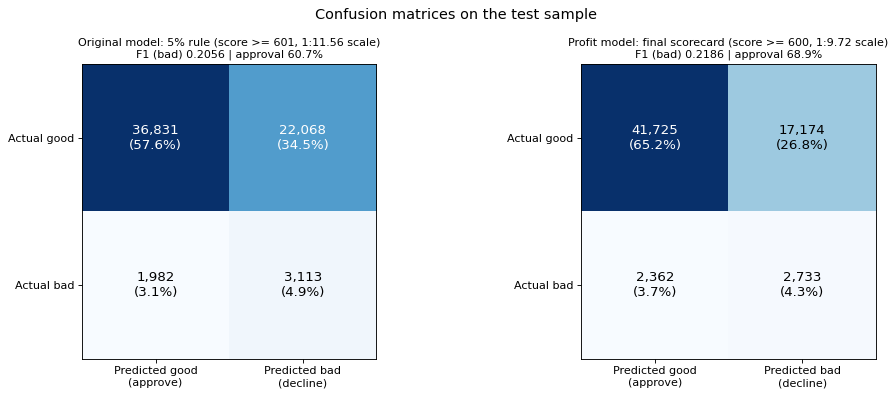

In [18]:
counts = ['TN (good approved)', 'FP (good declined)', 'FN (bad approved)', 'TP (bad declined)']
display(cm_table.loc[counts].style.format('{:,.0f}'))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, name in zip(axes, POLICIES):
    r = cm_results[('Test', name)]
    m = np.array([[r['TN (good approved)'], r['FP (good declined)']], [r['FN (bad approved)'], r['TP (bad declined)']]])
    ax.imshow(m, cmap='Blues')
    for (i, j), v in np.ndenumerate(m):
        ax.text(j, i, f'{v:,}\n({v / m.sum():.1%})', ha='center', va='center', fontsize=12,
                color='white' if v > m.max() / 2 else 'black')
    ax.set_xticks([0, 1]); ax.set_xticklabels(['Predicted good\n(approve)', 'Predicted bad\n(decline)'])
    ax.set_yticks([0, 1]); ax.set_yticklabels(['Actual good', 'Actual bad'])
    ax.set_title(f"{name}\nF1 (bad) {r['F1 (bad)']:.4f} | approval {r['Approval rate']:.1%}", fontsize=10)
plt.suptitle('Confusion matrices on the test sample', fontsize=13)
plt.tight_layout()
plt.show()

### 2. F1 score and 3. other evaluation measures

In [19]:
measures = ['F1 (bad)', 'Accuracy', 'Precision (bad)', 'Recall / sensitivity (bad)', 'Specificity', 'Approval rate', 'Approved bad rate']
display(cm_table.loc[measures].style.format('{:.4f}'))

change = pd.DataFrame({s: cm_table[(s, PROFIT)] - cm_table[(s, ORIGINAL)] for s in ['Train', 'Test']})
display(Markdown('**Profit model minus original model**'))
display(change.style.format('{:+,.4f}', subset=pd.IndexSlice[measures, :]).format('{:+,.0f}', subset=pd.IndexSlice[counts, :]))

# the same comparison in money: expected and realised net profit of the applicants each policy approves
def net_profit(df, approved):
    margin = (df['Revenue'] - df['Funding cost'] - df['Operating cost']).values[approved]
    return {'Expected net profit': (margin - df['Expected credit loss'].values[approved]).sum(),
            'Realised net profit (observed defaults)': (margin - df['Realised credit loss'].values[approved]).sum()}

money = {}
for sample, df in [('Train', train), ('Test', test)]:
    for name, rule in POLICIES.items():
        money[(sample, name)] = net_profit(df, rule(df))
money = pd.DataFrame(money)
for sample in ['Train', 'Test']:
    money[(sample, 'Change')] = money[(sample, PROFIT)] - money[(sample, ORIGINAL)]
money = money[[(s, c) for s in ['Train', 'Test'] for c in [ORIGINAL, PROFIT, 'Change']]]
display(Markdown(f'**Net profit of the approved applicants ({unit})**'))
display(money.style.format('{:,.0f}'))

**Profit model minus original model**

,Train,Test
TN (good approved),"+11,352","+4,894"
FP (good declined),"-11,352","-4,894"
FN (bad approved),"+1,109",+380
TP (bad declined),"-1,109",-380
F1 (bad),+0.0074,+0.0130
Accuracy,+0.0686,+0.0705
Precision (bad),+0.0106,+0.0137
Recall / sensitivity (bad),-0.0933,-0.0746
Specificity,+0.0826,+0.0831
Approval rate,+0.0835,+0.0824


**Net profit of the approved applicants (source currency units)**

**What we found (test sample, unseen applicants)**

**1. Confusion matrix.**
- The profit model approves **4,894 more good borrowers** (36,831 to 41,725) and **380 more bad borrowers** (1,982 to 2,362) than the original model: about 13 extra good loans for every extra bad one.
- The approval rate rises from 60.7% to 68.9%, and the bad rate among approved applicants from 5.11% to 5.36%.

**2. F1 score.**
- F1 for the bad class rises from **0.206 to 0.219** on test (0.212 to 0.220 on training).
- The declined group gets slightly "purer": precision rises more than recall falls in F1 terms.

**3. Other measures.**
- **Specificity** (good borrowers approved) rises from 0.625 to 0.708: we turn away fewer good customers.
- **Recall** (bad borrowers declined) falls from 0.611 to 0.536: the price of approving more applicants.
- **Precision (bad)** rises from 0.124 to 0.137.
- **Accuracy** rises from 0.624 to 0.695, mostly because we approve more of the majority class. With 7.96% bads, accuracy alone is not a good guide.

**Money.**
- Realised net profit (actual defaults) rises by about **50.5 million** on training and **51.2 million** on test.
- Expected net profit rises by 60.2 million and 24.8 million.

**Conclusion.** The profit model is better on F1, specificity, precision, accuracy and profit, at the cost of lower recall and a 0.25-point higher bad rate. That is the trade-off we intended: we chose the cutoff on profit, not F1. The results agree between training and test, so the policy holds up on unseen applicants.

## 7.8 Final Quality Assurance

End-to-end checks that our final characteristics are consistent from Step 5 to Step 7, and that the data, split and WOE mappings are unchanged.

In [20]:
encoded_saved = pd.read_csv('data/encoded.csv')
prepared_ref = pd.read_csv('data/prepared_data.csv', usecols=[ID, TARGET]).set_index(ID)
final_chars = [c for c in final_original.columns if c not in (ID, TARGET)]
qa = {
    'final_characteristics.csv = the Step 5 final characteristics': final_chars == list(approved_bins['woe']) == X_COLS,
    'encoded.csv = one WOE column per final characteristic': [c for c in encoded_saved.columns if c.endswith('_woe')] == [f'{c}_woe' for c in X_COLS],
    'Model inputs = final characteristics minus coefficient-sign exclusions': list(lr.feature_names_in_) == [f'{c}_woe' for c in X_COLS if c not in REMOVED_FOR_SIGN],
    'Every model coefficient has the expected (+) sign': bool((lr.coef_[0] > 0).all()),
    'Scorecard points table covers exactly the model characteristics': set(scorecard_table['Characteristic']) == set(MODEL_X) and set(card) - {'basepoints'} == set(MODEL_X),
    'scorecardpy WOE equals the Step 5 WOE (sign reversed)': all(
        np.allclose(np.sort(bins[v]['woe'].values), np.sort(-np.array(list(approved_bins['woe'][v].values()))), atol=1e-6) for v in MODEL_X),
    'Profitability uses the model scores': train['score'].equals(pd.Series(sc.scorecard_ply(train[MODEL_X], card)['score'].values, name='score')),
    'Applicant row count unchanged (213,312)': len(final_original) == len(prepared_ref) == len(train) + len(test) == len(encoded_saved),
    'TARGET unchanged vs prepared_data.csv': (final_original.set_index(ID)[TARGET] == prepared_ref.loc[final_original[ID], TARGET]).all(),
    'Train/test assignment identical to train_test_split.csv': (encoded_saved.set_index(ID)['DATA_SPLIT'].str.lower() == split_ids.set_index(ID).loc[encoded_saved[ID], 'SAMPLE']).all(),
    'No applicant in both samples (no leakage)': set(train[ID]).isdisjoint(test[ID]),
    'Cutoff and scaling chosen on training data only': bool(OPT_CUTOFF in cutoffs_train['Cutoff'].values),
}
qa_table = pd.DataFrame({'Passed': qa})
display(qa_table)
assert qa_table['Passed'].all()
print('All quality-assurance checks passed')

,Passed
final_characteristics.csv = the Step 5 final characteristics,True
encoded.csv = one WOE column per final characteristic,True
Model inputs = final characteristics minus coefficient-sign exclusions,True
Every model coefficient has the expected (+) sign,True
Scorecard points table covers exactly the model characteristics,True
scorecardpy WOE equals the Step 5 WOE (sign reversed),True
Profitability uses the model scores,True
"Applicant row count unchanged (213,312)",True
TARGET unchanged vs prepared_data.csv,True
Train/test assignment identical to train_test_split.csv,True


All quality-assurance checks passed


## 7.9 Final Summary

In [21]:
applied = FINAL_SCALING_APPROVED
f_factor = FINAL_PDO / np.log(2)
f_offset = FINAL_POINTS0 + f_factor * np.log(FINAL_ODDS0)
pol = policy(cutoffs_train, OPT_CUTOFF)
display(Markdown(f'''
### A. Sensitivity analysis

The complete table and graph are in 7.3 (training sample, {unit}, {HORIZON}). Assumptions: revenue {INTEREST_FEE_RATE:.0%}, funding {FUNDING_COST_RATE:.0%}, operating cost {OPERATING_COST_RATE:.0%} of EAD; LGD {LGD:.0%}; break-even PD {BREAK_EVEN_PD:.2%}.

### B. Recommended lending policy

| | Value |
|---|---|
| Profit-maximising risk tolerance | {OPT_TOLERANCE:.1%} |
| Optimal cutoff (reference scale) | {OPT_CUTOFF} |
| Approval rate (train) | {pol["Approval rate"]:.1%} |
| Actual approved bad rate (train) | {pol["Approved bad rate"]:.2%} |
| Expected credit loss (train) | {pol["Expected credit loss"]:,.0f} |
| Expected net profit (train) | {pol["Expected net profit"]:,.0f} |
| Change in expected net profit vs the original 5% policy (train / test) | {delta_train:+,.0f} / {delta_test:+,.0f} |

### C. Final scorecard scaling ({"APPLIED" if applied else "NOT YET APPLIED"})

| | Value |
|---|---|
| Target score | {FINAL_POINTS0} |
| Target odds (bad:good) | 1 : {1 / FINAL_ODDS0:.2f} |
| PDO | {FINAL_PDO} |
| Factor | {f_factor:.4f} |
| Offset | {f_offset:.2f} |
| Final operating cutoff | {FINAL_CUTOFF} |

### D. Business interpretation

- **Economic improvement.** Moving from the original 5% policy (cutoff {RULE5_CUTOFF}) to the profit-maximising cutoff changes expected net profit by {delta_train:+,.0f} {unit} on the training sample ({delta_test:+,.0f} on test), and realised net profit by {realised_policy:+,.0f}. The gain comes from approving applicants whose expected margin exceeds their expected credit loss.
- **Scorecard presentation.** Re-anchoring 600 at the odds of the chosen cutoff (1 : {1 / FINAL_ODDS0:.2f}) makes the approval line read as 600. It changes the numbers on the scorecard, not who is approved (apart from rounding at the boundary), the ranking, the PDs or the AUC.
'''))


### A. Sensitivity analysis

The complete table and graph are in 7.3 (training sample, source currency units, 1 year). Assumptions: revenue 12%, funding 4%, operating cost 2% of EAD; LGD 60%; break-even PD 10.00%.

### B. Recommended lending policy

| | Value |
|---|---|
| Profit-maximising risk tolerance | 5.5% |
| Optimal cutoff (reference scale) | 595 |
| Approval rate (train) | 70.8% |
| Actual approved bad rate (train) | 5.48% |
| Expected credit loss (train) | 2,057,259,344 |
| Expected net profit (train) | 1,824,348,853 |
| Change in expected net profit vs the original 5% policy (train / test) | +64,825,208 / +26,817,342 |

### C. Final scorecard scaling (APPLIED)

| | Value |
|---|---|
| Target score | 600 |
| Target odds (bad:good) | 1 : 9.72 |
| PDO | 20 |
| Factor | 28.8539 |
| Offset | 534.38 |
| Final operating cutoff | 600 |

### D. Business interpretation

- **Economic improvement.** Moving from the original 5% policy (cutoff 601) to the profit-maximising cutoff changes expected net profit by +64,825,208 source currency units on the training sample (+26,817,342 on test), and realised net profit by +49,478,009. The gain comes from approving applicants whose expected margin exceeds their expected credit loss.
- **Scorecard presentation.** Re-anchoring 600 at the odds of the chosen cutoff (1 : 9.72) makes the approval line read as 600. It changes the numbers on the scorecard, not who is approved (apart from rounding at the boundary), the ranking, the PDs or the AUC.


### E. Limitations

- **Financial assumptions.** Revenue 12%, funding 4% and operating cost 2% of the loan amount, and LGD 60%, are our own illustrative assumptions.
  - The best cutoff depends mainly on the break-even PD (margin divided by LGD).
  - Loan amounts are in source currency units (currency not stated), not SGD.
- **Horizon and what "bad" means.** `TARGET` flags early payment difficulties, not default over the whole loan. We assume a single one-year horizon.
- **PD calibration.** The PDs are well calibrated by decile on train and test, but could drift for future applicants. Profit is sensitive to PD levels near the break-even point.
- **Selection sample.** We have no separate validation sample. We chose the cutoff on the training sample, cross-checked it with out-of-fold PDs and confirmed it on test.
- **Exposure.** EAD is the full approved amount; we ignore amortisation, prepayment and recoveries.
- **Model discrimination.** Test Gini is 0.34, so goods and bads overlap quite a lot in score.
- **Arrears.** The bureau arrears measures fell below the predictive-power threshold in Step 5, so past repayment problems only come in indirectly, through credit exposure, recent credit activity and microloans.
- **Historical bad rates.** We only have outcomes for applicants the lender approved in the past (no reject inference).

In [22]:
# inputs unchanged
assert pd.read_csv('data/final_characteristics.csv').equals(final_original)
print('final_characteristics.csv unchanged; notebook complete')

final_characteristics.csv unchanged; notebook complete
